# Week 5 - Regularisation

**Thomas Sinclair**

## Aims

By the end of this notebook you will be able to 

>* perform regulized regression in sklearn
>* understand the role of tuning parameter(s)
>* use cross-validation for model tuning and comparison.

1. [Problem Definition and Setup](#setup)
2. [Exploratory Data Analysis](#eda)
3. [Baseline Model](#baseline)
4. [Ridge Regression](#ridge)
4. [Lasso Regression](#lasso)
4. [ElasticNet Regression](#elasticnet)

You may complete the worksheets together in teams of 2-3. When completing worksheets:

>- You will have tasks tagged by (CORE) and (EXTRA). 
>- Your primary aim is to complete the (CORE) components during the WS session, afterwards you can try to complete the (EXTRA) tasks for your self-learning process. 

Instructions for submitting your workshops can be found at the end of worksheet. As a reminder, you must submit a pdf of your notebook on Learn by 16:00 PM on the first Monday after the day workshop was given.

---

# Problem Definition and Setup<a id='setup'></a>

## Packages

First, let's load some of the packages you wil need for this workshop (we will load others as we progress).

In [2]:
# Data libraries
import pandas as pd
import numpy as np
import math

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, KFold

## User Defined Helper Functions

We will make use of the two helper functions. The first is identical to the one last week. The second one extract the coefficients and names (if required), plots the coefficients and returns a data frame. 

In [3]:
def model_fit(m, X, y, plot = False):
    """Returns the mean squared error, root mean squared error and R^2 value of a fitted model based 
    on provided X and y values.
    
    Args:
        m: sklearn model object
        X: model matrix to use for prediction
        y: outcome vector to use to calculating rmse and residuals
        plot: boolean value, should residual plots be shown 
    """
    
    y_hat = m.predict(X)
    MSE = mean_squared_error(y, y_hat)
    RMSE = math.sqrt(MSE)
    Rsqr = r2_score(y, y_hat)
    
    Metrics = (round(MSE, 4), round(RMSE, 4), round(Rsqr, 4))
    
    res = pd.DataFrame(
        data = {'y': y, 'y_hat': y_hat, 'resid': y - y_hat}
    )
    
    if plot:
        plt.figure(figsize=(12, 6))
        
        plt.subplot(121)
        sns.lineplot(x='y', y='y_hat', color="grey", data =  pd.DataFrame(data={'y': [min(y),max(y)], 'y_hat': [min(y),max(y)]}))
        sns.scatterplot(x='y', y='y_hat', data=res).set_title("Observed vs Fitted values")
        
        plt.subplot(122)
        sns.scatterplot(x='y_hat', y='resid', data=res).set_title("Fitted values vs Residuals")
        plt.hlines(y=0, xmin=np.min(y), xmax=np.max(y), linestyles='dashed', alpha=0.3, colors="black")
        
        plt.subplots_adjust(left=0.0)
        
        plt.suptitle("Model (MSE, RMSE, Rsq) = " + str(Metrics), fontsize=14)
        plt.show()
    
    return MSE, RMSE, Rsqr

In [4]:
def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    """Returns model coefficients in a data frame for a fitted linear model.
    
    Args:
        m: sklearn LinearRegression model object or pipeline with LinearRegression as final step
        plot: boolean value, should coefficients be plotted with error bars
        feature_names: list of feature names to use in the plot 
        figsize: tuple defining figure size
        figtitle: string defining figure title
        intercept: boolean value, should intercept be included in the plot
    """
    
    # Extract intercept and coefficients into a single array
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_], 
                            m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    # Extract name of features
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
    feature_names = np.concatenate((['intercept'], feature_names))
    # Create a data frame
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values ("coef", ascending=False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
        plt.figure(figsize=figsize)
        plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features')
        plt.xlabel('Coefficient Value')
        plt.axvline(x=0, color=".5")
        if figtitle is not None:
            plt.title(figtitle)
        plt.grid()
        plt.show()
    
    return  w_df

## Data

The data for this week's workshop comes from the Elements of Statistical Learning textbook. The data originally come from a study by [Stamey et al. (1989)](https://www.sciencedirect.com/science/article/abs/pii/S002253471741175X)  in which they examined the relationship between the level of prostate-specific antigen (`psa`) and a number of clinical measures in men who were about to receive a prostatectomy. The variables are as follows,

* `lpsa` - log of the level of prostate-specific antigen
* `lcavol` - log cancer volume
* `lweight` - log prostate weight
* `age` - patient age
* `lbph` - log of the amount of benign prostatic hyperplasia
* `svi` - seminal vesicle invasion
* `lcp` - log of capsular penetration
* `gleason` - Gleason score
* `pgg45` - percent of Gleason scores 4 or 5
* `train` - test / train split used in ESL

These data are available in `prostate.csv`, which is included in the workshop materials.

Let's start by reading in the data.

In [5]:
prostate = pd.read_csv('prostate.csv')
prostate.head()

,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45,lpsa,train
0,-0.579818,2.769459,50,-1.386294,0,-1.386294,6,0,-0.430783,T
1,-0.994252,3.319626,58,-1.386294,0,-1.386294,6,0,-0.162519,T
2,-0.510826,2.691243,74,-1.386294,0,-1.386294,7,20,-0.162519,T
3,-1.203973,3.282789,58,-1.386294,0,-1.386294,6,0,-0.162519,T
4,0.751416,3.432373,62,-1.386294,0,-1.386294,6,0,0.371564,T


# Exploratory Data Analysis<a id='eda'></a>

Before modelling, we will start with EDA to gain an understanding of the data, through descriptive statistics and visualisations. 

### 🚩 Exercise 1 (CORE)

a) Examine the data structure, look at the descriptive statistics, and create a pairplot. Do any of our variables appear to be categorical / ordinal rather than numeric?

b) Are there any interesting patterns in these data? Which variable appears likely to have the strongest relationship with `lpsa`? Why do you think we are exploring the relationship between these variables and `lpsa` (log of psa) rather than just psa?

(97, 10)
<class 'pandas.DataFrame'>
RangeIndex: 97 entries, 0 to 96
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   lcavol   97 non-null     float64
 1   lweight  97 non-null     float64
 2   age      97 non-null     int64  
 3   lbph     97 non-null     float64
 4   svi      97 non-null     int64  
 5   lcp      97 non-null     float64
 6   gleason  97 non-null     int64  
 7   pgg45    97 non-null     int64  
 8   lpsa     97 non-null     float64
 9   train    97 non-null     str    
dtypes: float64(5), int64(4), str(1)
memory usage: 7.7 KB


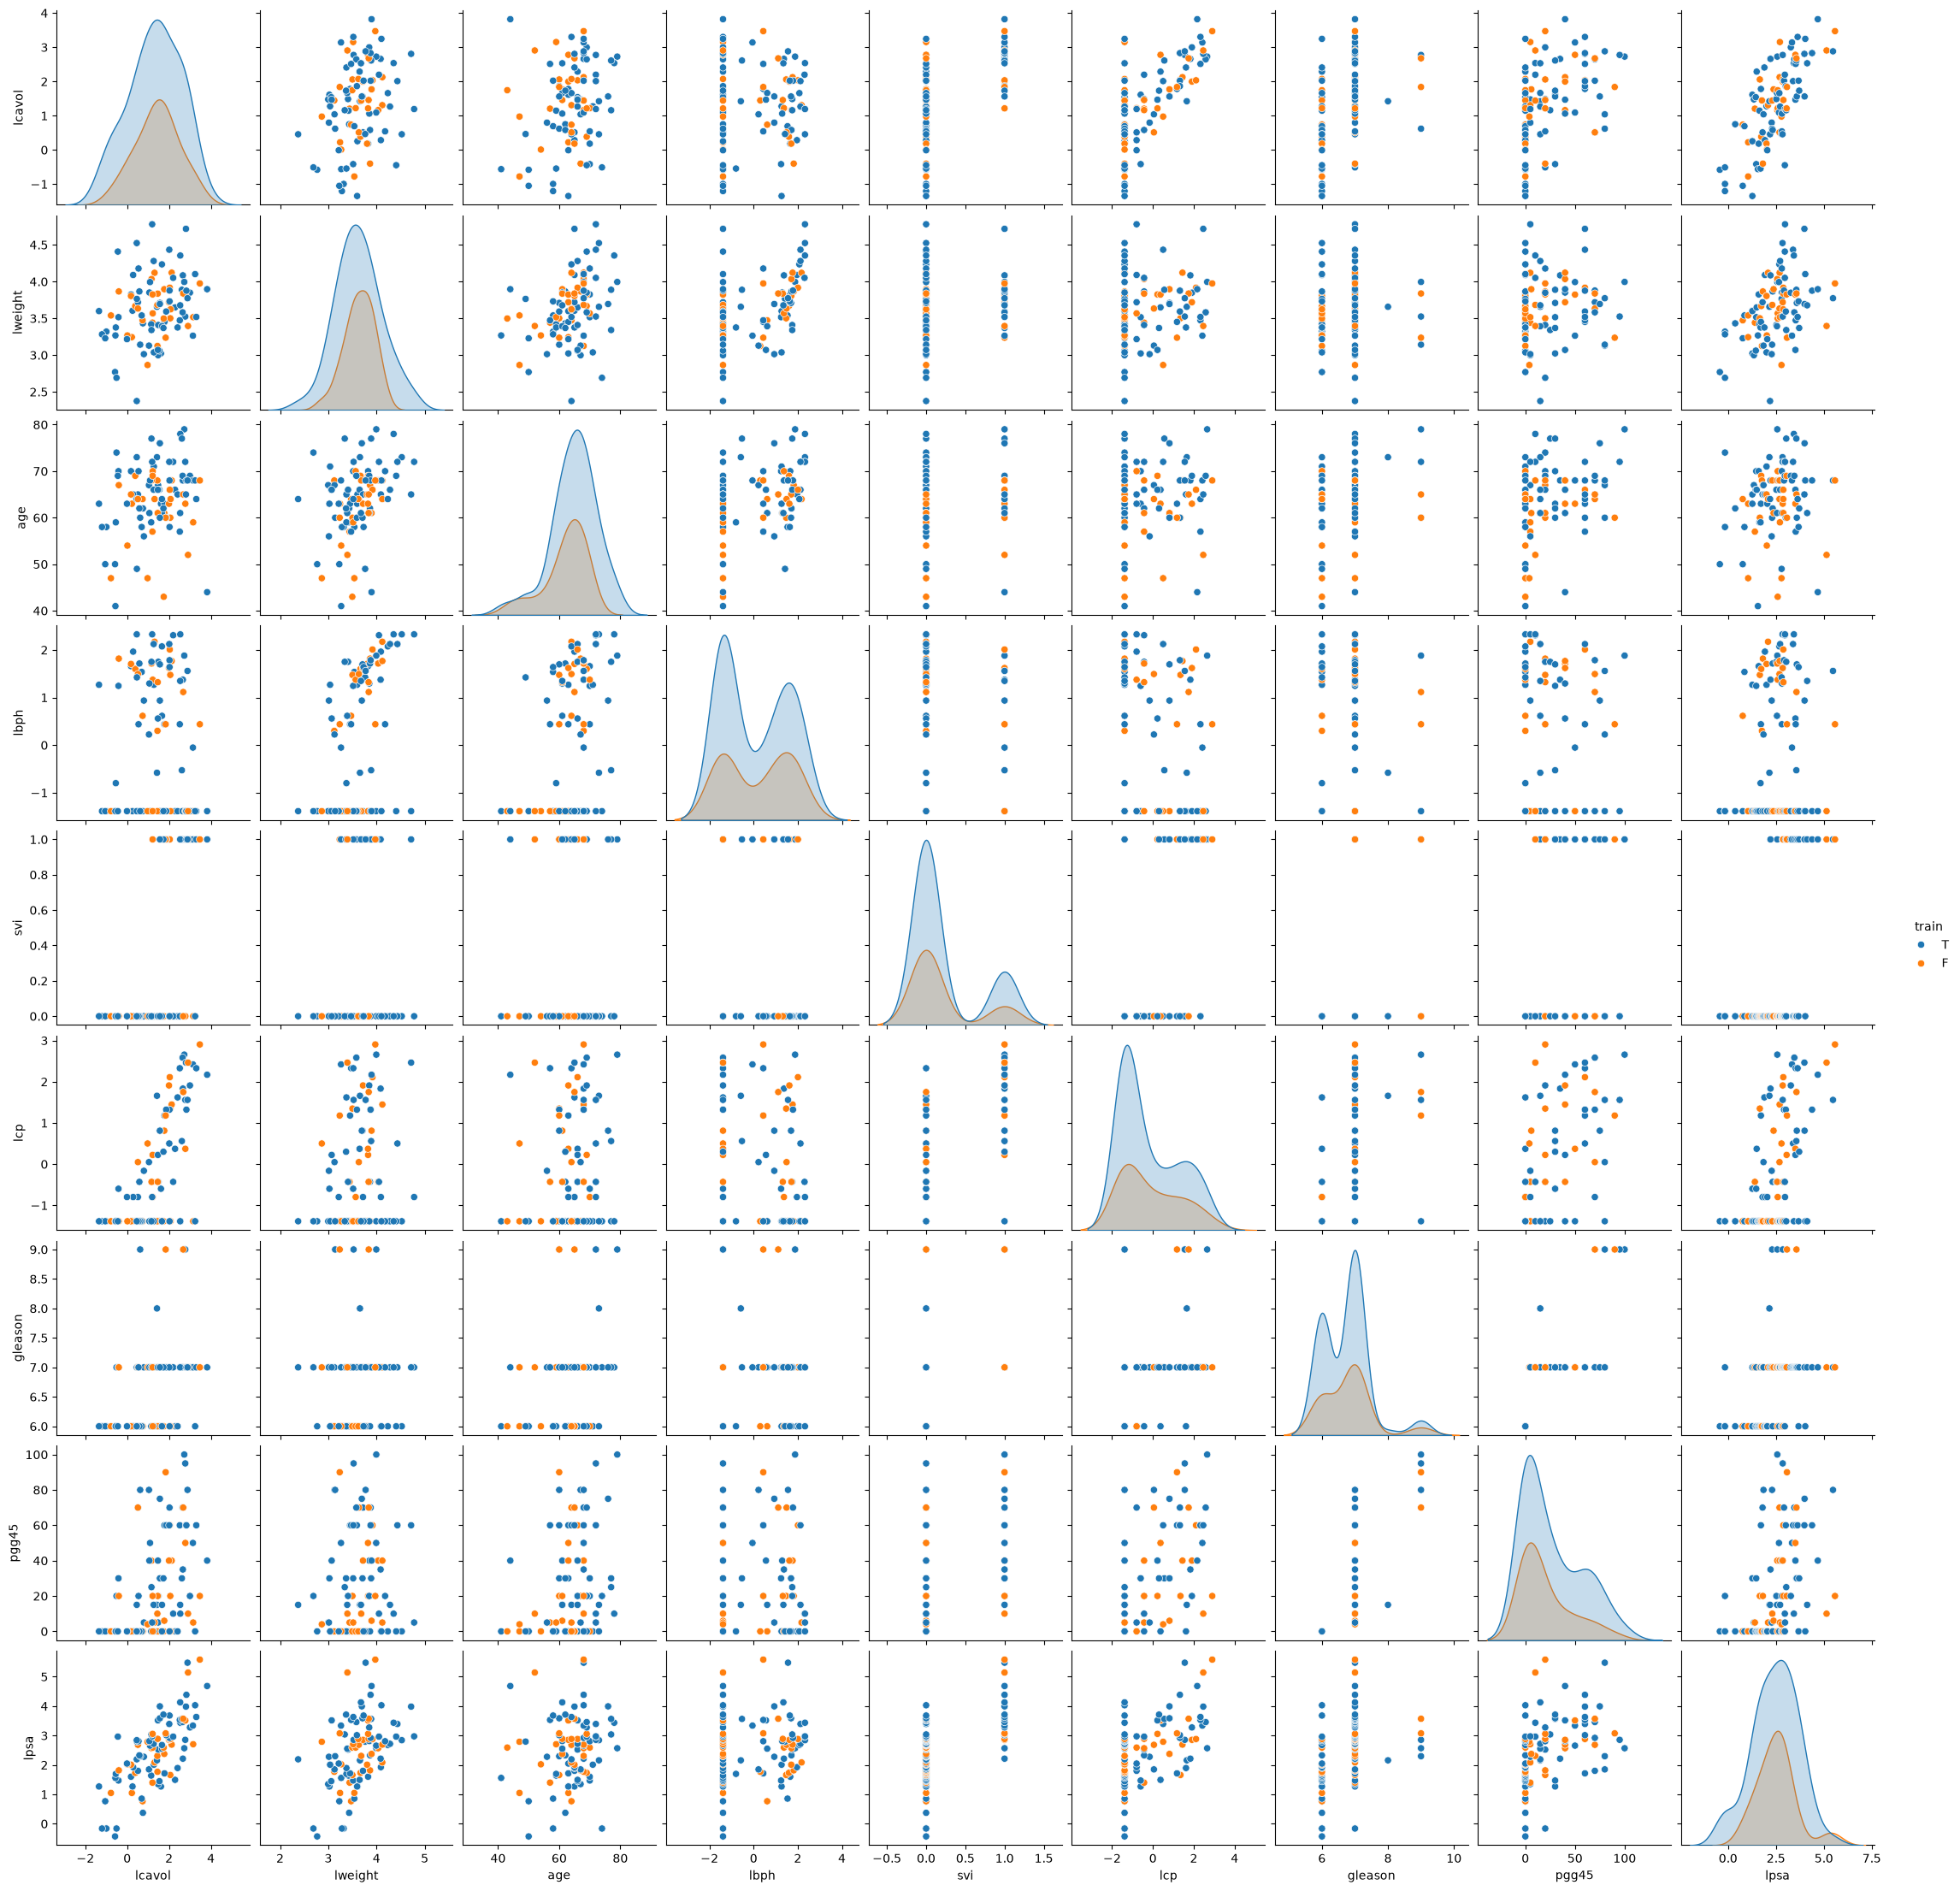

In [6]:
# Code for your answer here!
#(a)
print(prostate.shape)
prostate.info()
prostate.describe()
prostate.isnull().sum()

# (b) 
sns.pairplot(prostate, hue='train')
plt.show()
#
##sns.violinplot(x="children", y="charges", data=df_insurance, hue="smoker")
#plt.show()

#filtered_df = df_insurance[(df_insurance['children'] == 5) & (df_insurance['smoker'] == 'yes')]
#print(filtered_df)

_Type your answer here_

(a) Here looking at the overview of the data we see we have a full set. Theres no null values, and most columns are floats values, with 5 being floats, 4 being integers, and one string. The string simply tells you whether the data is training or test, thus a categorical varables, as no clear ranking. When looking at the pairplot, we see some distinct patterns when looking at specific variables. Starting from the left column going right, we see the first that catches the eye, is the ibph plots. There's a distinct straight line just above -2, where there are many points, as seen in the density plot. This relationship is apparent in both training and test data. However this is numerical as is a float value, possibly jsut has grouping. 

A clear categorical variable is the svi, Where we clearly see two values for all data points. either 0, or 1. Could be oridnal if this could be ranked. The same can be said for gleason, but just with more catgories. Hence it's either a categorical variables, or a ordinal, depending on whether theres a ranking.

(b) Looking at patterns related to lpsa, we see a possible linear relationship between lpsa, and lcavol. This is most prominent in this case, but we also see linear relatonships with lweight, lcp, and pgg45. lpsa is the log of the level of prostate-specific antigen. We are looking for the relationship between the level of prostate-specific antigen (`psa`) and a number of clinical measures in men who were about to receive a prostatectomy. Thus looking at variables with distinct relationships with the log of that is a great way to also find patterns with psa itself. Looking at the log, compresses large values, and stretches out smaller values, thus normalising the data, reducing variance doing so.

## Train-Test Set <a id='gen'></a>

For these data we have already been provided a column to indicate which values should be used for the training set and which for the test set. This is encoded by the values in the `train` column - we can use these columns to separate our data and generate our training data: `X_train` and `y_train` as well as our test data `X_test` and `y_test`. 

In [7]:
# Create train and test data frames
train = prostate.query("train == 'T'").drop('train', axis=1)
test = prostate.query("train == 'F'").drop('train', axis=1)

In [8]:
# Training data
X_train = train.drop(['lpsa'], axis=1)
y_train = train.lpsa

print('X_train:', X_train.shape)
print('y_train:', y_train.shape)


X_train: (67, 8)
y_train: (67,)


In [9]:
# Test data
X_test = test.drop('lpsa', axis=1)
y_test = test.lpsa

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_test: (30, 8)
y_test: (30,)


Let's also fix the random seed to make this notebook's output identical at every run

In [10]:
# Fix seed
rng = np.random.seed(0)

# Baseline model<a id='baseline'></a>

Our first task is to fit a baseline model which we will be able to use as a point of comparison for our subsequent models. A good candidate for this is a simple linear regression model that includes all of our features.

In [11]:
# Train a linear regression model
from sklearn.linear_model import LinearRegression
lm = LinearRegression().fit(X_train, y_train)

Using our helper function, we can extract the coefficients for the model, which correspond to the variables: `lcavol`, `lweight`, `age`, `lbph`, `svi`, `lcp`, `gleason`, and `pgg45` respectively.

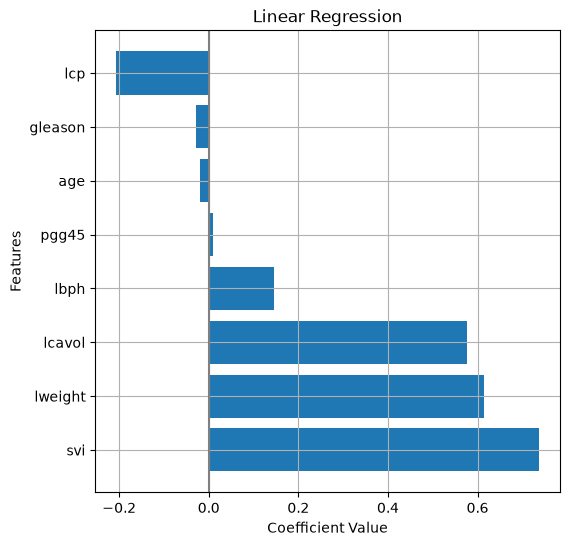

In [12]:
w_df = get_coefs(lm, plot=True, figsize=(6,6), figtitle="Linear Regression", intercept=False)

These coefficients have the typical regression interpretation, e.g. for each unit increase in `lcavol` we expect `lpsa` to increase by 0.5765 on average. To evaluate the predictive properities of our model, we will use the `model_fit` helper function.

### 🚩 Exercise 2 (CORE)

Use the `model_fit` function to evaluate both the model fit on the training data and the predictions on the test data. 

- Based on these plots do you see anything in the fit or residual plot that is potentially concerning? 
- Do you expect the MSE on test data to be better or worse than the MSE on the training data?

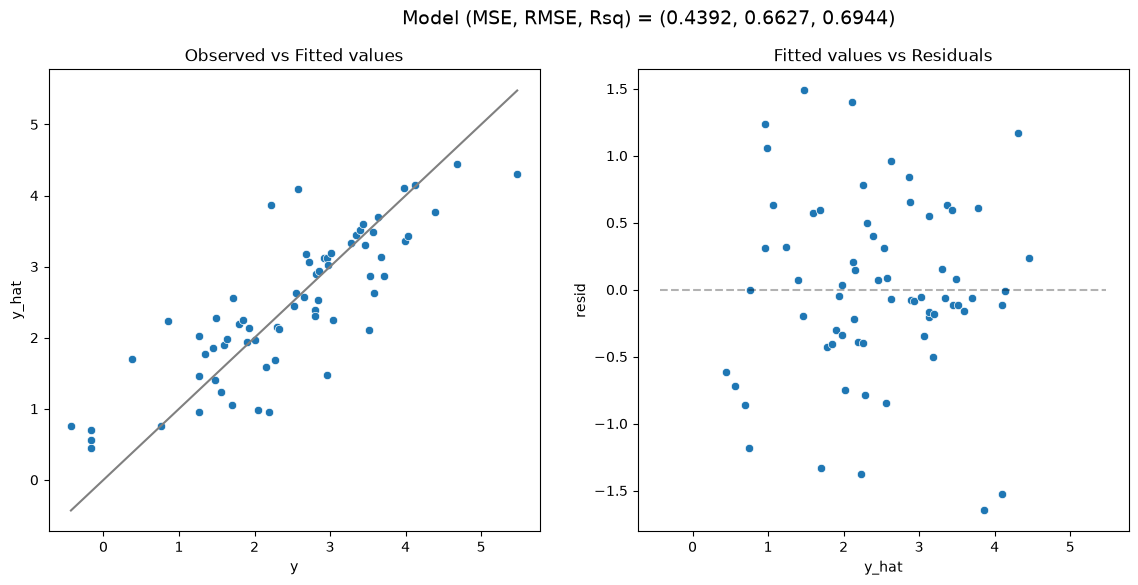

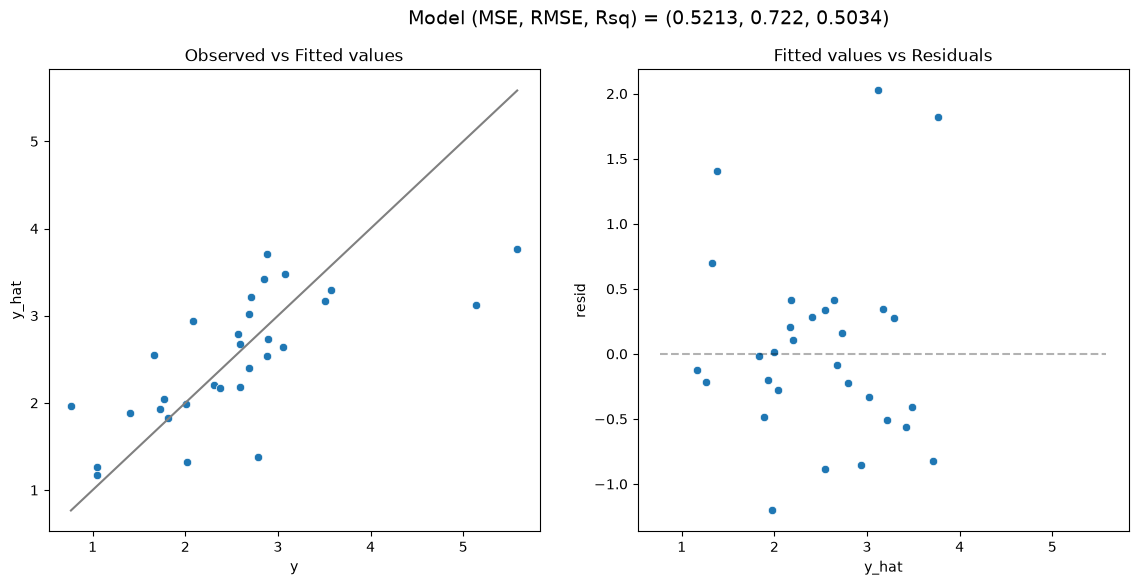

(0.5212740055076023, 0.7219930785731967, 0.5033798502381788)

In [13]:
# Code for your answer here!

model_fit(lm, X_train, y_train, plot = True)

model_fit(lm, X_test, y_test, plot = True)

_Type your answer here_

Looking at both the fit and residual plots for training and test data, we see that both seem relatively unconcerning. The one thing that may be concerning is how much higher the MSE of the test data is. But if anything this jsut shows the model is correctly implemented to take into account the linearity of the training data. Theres also a lareg differnece in R squared value, with training having almost 0.2 higher R squared value, meaning the model fits traiing data much better. Thus could imply some bias towards the training data, or jud general variance, as test data is smaller. Higher MSE for test data also implies that the model could be overfit.

## Standardisation

In subsequent sections we will be exploring the use of the Ridge and Lasso regression models which both penalise larger values of $\mathbf{w}$. While not particularly bad, our baseline model had coefficients that ranged from the smallest at 0.0095 to the largest at 0.737 which is about a 78x difference in magnitude. This difference can be made even worse if we were to change the units of one of our features, e.g. changing a measurement in kg to grams would change that coefficient by 1000 which has no effect on the fit of our linear regression model (predictions and other coefficients would be unchanged) but would have a meaningful impact on the estimates given by a Ridge or Lasso regression model, since that coefficient would now dominate the penalty term.

To deal with this issue, the standard approach is to standaridise all features. Additionally, the feature values can now be interpreted as the number of standard deviations each observation is away from that column's mean.
Using `sklearn` we can perform this transformation using the `StandardScaler` transformer from the preprocessing submodule.

Keep in mind, that in order to avoid **data leakage** and get a realistic idea of the performance of model on the test data, **the mean and standard deviation used to standardise both the training and test sets should be computed from the training data only**.  The best way to accomplish this is to include the StandardScaler in a modeling pipeline for your data.

### 🚩 Exercise 3 (CORE)

Consider the following pipeline that first standardises the numeric features before linear regression. Fit the model to the training data.  Using this new model what has changed about our model results? Comment on both the model's coefficients as well as its predictive performance. How has the interpretation of coefficients changed?

In [14]:
# Linear regression pipeline, including standardisation
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder

# Names of numeric features
num_features = ['lcavol','lweight','age', 'lbph','lcp', 'pgg45']
# Names of binary features
bin_features = ['svi']
ord_features = ['gleason']

preprocessor = make_column_transformer(
    (StandardScaler(), num_features),
    (OrdinalEncoder(categories=[[6,7,8,9]]),ord_features),
    ('passthrough', bin_features),
    verbose_feature_names_out=False
)

lm_s = make_pipeline(
    preprocessor,
    LinearRegression()
).fit(X_train, y_train)

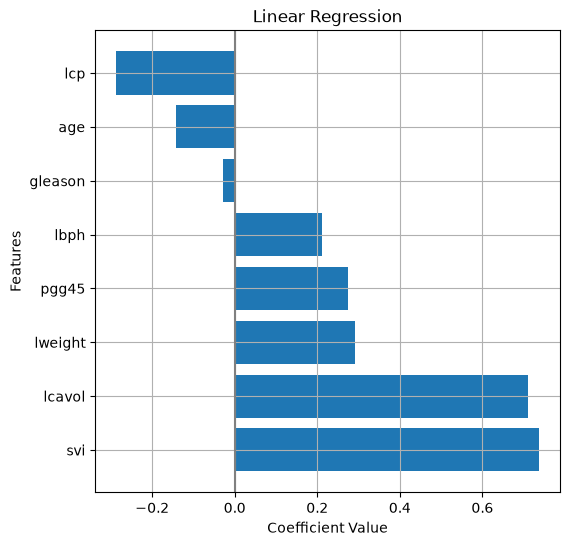

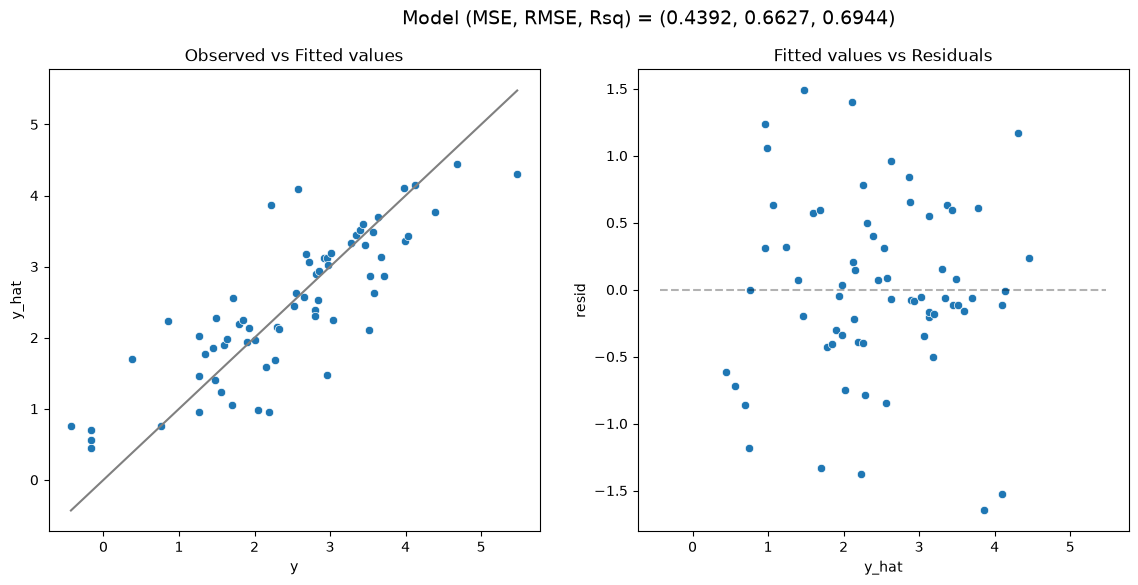

(0.4391997680583343, 0.662721486039448, 0.6943711796768238)

In [15]:
# Code for your answer here!

w_df = get_coefs(lm_s, plot=True, figsize=(6,6), figtitle="Linear Regression", intercept=False)

model_fit(lm_s, X_train, y_train, plot = True)

_Type your answer here_

Looking at the coefficiients and fitted values, as well as resduals for this new model we see something interesting. The model outputs the same level of predictive performance, with the MSE and R-squared being the same of the previous model on the training data, as expected due to standardisation. However, what is different here is the weighting on the coefficients of the parameters in this model. Some notebale changes, is age becoming a much larger negative coefficients. And, the log weight essentially halving. Our coefficients now are on a standard deviation scale as well. Where one standard deviation increase in a feature is associated with a change in variable equal to the coefficient value.

# Ridge Regression<a id='ridge'></a>

Ridge regression is a natural extension to linear regression which introduces an $\ell_2$ penalty on the coefficients in a standard least squares problem. 

The [`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) model is provided by the `linear_model` submodule. Note that the penalty parameter (referred to as $\lambda$ in the lecture notes) is called `alpha` is sklearn, and, as discussed in lectures, this parameter crucially determines the amount of shrinkage towards zero and the weight of the $\ell_2$ penalty.

After defining the ridge regression model via, e.g. `Ridge(alpha = 1)`, the usual methods can be called, such as `.fit()` to fit the model and `.predict()` to make predictions. 

As for the `LinearRegression()`, after fitting, the intercept and coefficients are stored separately in the attributes `.intercept_` and `.coef_`. In Ridge, this is helpful as it highlights how the penalty is only applied to the coefficient (i.e. we do not want to shrink the intercept).  

Let's start by fitting a ridge regression model with $\alpha=1$.

In [16]:
from sklearn.linear_model import Ridge

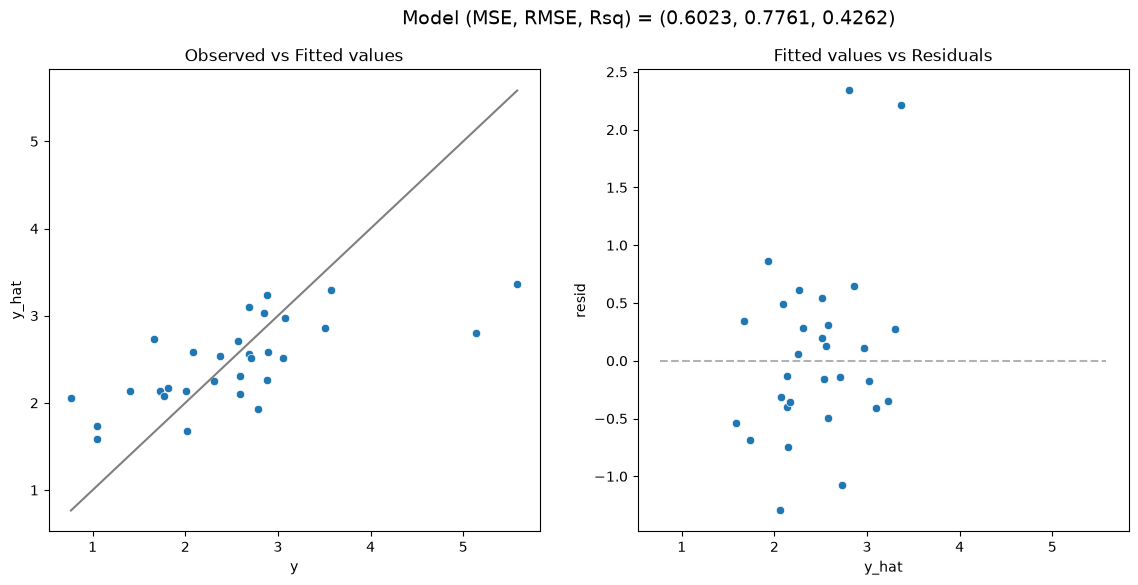

(0.6022994181435168, 0.776079517925526, 0.4261865658376307)

In [17]:
# Selected alpha value 
alpha_val = 100

# Ridge pipeline
r = make_pipeline(
    preprocessor,
    Ridge(alpha = alpha_val)
).fit(X_train, y_train)

model_fit(r, X_test, y_test, plot = True)

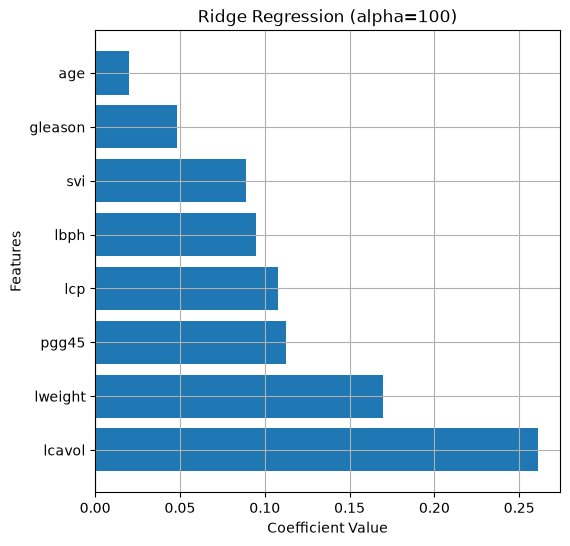

In [18]:
w_dr_r = get_coefs(r, plot=True, figsize=(6,6), figtitle="Ridge Regression (alpha="+str(alpha_val)+")", intercept=False)

### 🚩 Exercise 4 (CORE)

Adjust the value of `alpha` in the cell above and rerun it. Qualitatively, how does the model fit change as alpha changes? How does the MSE change? 


_Type your answer here_

For the original alpha value of 1, we see a model fit corresponding to MSE of 0.51, and a R-squared value of, 0.51. Our coefficient values are similar to the one in the previous models with lcavol being large, along with svl. And, lcp, and age being smaller and negative.  If we increase the alpha value to 5, we see a substantial change. Our MSE is 0.50, along with a R-squared value of 0.52. meaning the model fits the data better, as MSe is smaller, and R-squared is closer to 1. What is the obvious chnage however, is the weighting of the coefficients. All the negaitve coefiicicnets get heavily scaled towards the positive axis, with gleason even becoming positive. As well as that, the positive weight become even more positive, with te lcavol with a weight of around 6.5, which is a large increase from previous alpha. 

Now increasing to alpha = 100, we see that the MSE is 0.6, and R-squared is 0.43. Thus our model has become a worse fit. Thus the MSE has turned back around and is getting worse. We know there is some optimal alpha value which minimises MSE, somewhere between alpha = 5 and 100. We see this could be due to the distortion of the parameter coefficients, where all are now slightly positive (and tending to zero in notes i think?).


## Solution path: Ridge coeffcients as a function of $\alpha$

A useful way of examining the behaviour of Ridge regression models is to plot the **solution path** of the coefficents $\mathbf{w}$ as a function of the penalty parameter $\alpha$. Since Ridge regression is equivalent to linear regression when $\alpha=0$, we can see that as we increase the value of $\alpha$, we are shrinking all of the coefficients in $\mathbf{w}$ towards zero asymptotically $\alpha$ approaches infinity.

In [99]:
# Grid of alpha values
alphas = np.logspace(-2, 100, num=200) # from 10^-2 to 10^3

ws = [] # Store coefficients
mses_train = [] # Store training mses
mses_test = [] # Store test mses

for a in alphas:
    m = make_pipeline(
        preprocessor,
        Ridge(alpha=a)
    ).fit(X_train, y_train)
    
    ws.append(m[-1].coef_) 
    mses_train.append(mean_squared_error(y_train, m.predict(X_train)))
    mses_test.append(mean_squared_error(y_test, m.predict(X_test)))


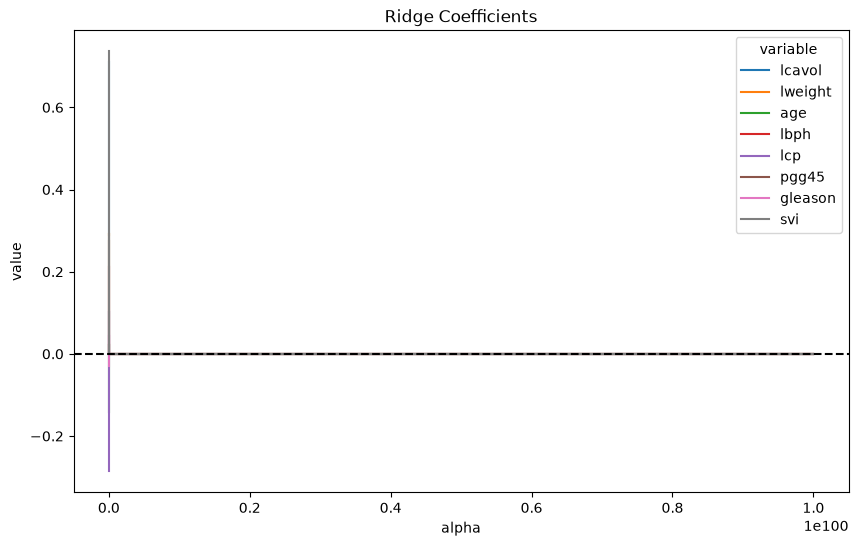

In [100]:
# Create a data frame for plotting
sol_path = pd.DataFrame(
    data = ws,
    columns = m[0].get_feature_names_out()
).assign(
    alpha = alphas,
).melt(
    id_vars = ('alpha')
)

# Plot solution path of the weights
plt.figure(figsize=(10,6))
ax = sns.lineplot(x='alpha', y='value', hue='variable', data=sol_path)
ax.axhline(y=0, color = "black", linestyle='dashed')
ax.set_title("Ridge Coefficients")
plt.show()

### 🚩 Exercise 5 (CORE)

Based on this plot, which variable(s) seem to be the most important for predicting `lpsa`?

_Type your answer here_

The Variables that seem to be the most important for predicitng lpsa are the ones that are decrease the least as alpha increases. I am colourblind so can't exactly tell you which ones they are but, the most important ones are the top one that consistently stays the highest value as alpha increases, and the bottom one that isnt initiallt the smallest, but after alpha increases from 1 it quickly becomes the smallest value.

### 🚩 Exercise 6 (CORE)

Run the code below to also plot both the training and test MSE as a function of $\alpha$. What do you notice about the MSE as we increase $\alpha$? Which value of $\alpha$ seems better regarding the changes on training and testing MSE values?

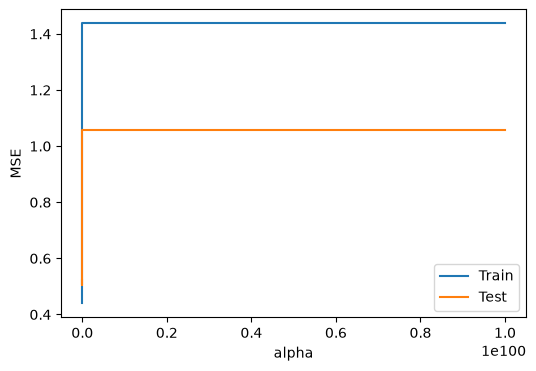

In [101]:
# Path of MSE as function of alpha
mses_path = pd.DataFrame(
    {'alpha': alphas, 'Train': np.asarray(mses_train), 'Test': np.asarray(mses_test)}).melt(
    id_vars = ('alpha')
)

# Plot MSE path
plt.figure(figsize=(6,4))
ax = sns.lineplot(x='alpha', y='value', hue='variable', data=mses_path)
ax.set_ylabel("MSE")
# ax.set_xlim(0,200) # Optional: to zoom in on lower alpha values
# To remove legend title
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[0:], labels=labels[0:])
plt.show()


_Type your answer here_

We see something interesting happen to the model trained on the test data as we increase alpha. The MSE initially decreases when we increase alpha for the model fitted on the test data, then proceeds to increase. However, for the model tested on the training data we see that as alpha increases, the MSE monotonically increases from the start. As well as that, comparing the MSE values the model fitted on the training data is initilaly lower, but then quickly goes up, causing the fitted test data to have a lower mse as apha increases. The best alpha value therefore would be the one that minimises both fitted values. Graphiclly we see this is around the minimum of the test fitted values, which is an alpha just above 0.

## Tuning the penalty parameter with cross-validation

We see that the value of $\alpha$ crucially determines the performance of the ridge regression model. While `RidgeRegression()` uses the default value of `alpha=1`, this **should never be used in practice**. Instead, this parameter can be **tuned using cross-validation**. 

As with the polynomial models from last week, we can use `GridSearchCV` to employ k-fold cross validation to determine an optimal $\alpha$. Remember, you can use the method `.get_params()` on your pipeline to list the parameters names to specify in `GridSearchCV`.

In [22]:
# Grid of tuning parameters
alphas = np.linspace(0, 30, num=201)  

#Pipeline
m = make_pipeline(
        preprocessor,
        Ridge())
# To get the parameter name for grid search
# m.get_params()

# CV strategy
cv = KFold(5, shuffle=True, random_state=1234)

# Grid search
gs = GridSearchCV(m,
    param_grid={'ridge__alpha': alphas},
    cv=cv,
    scoring="neg_mean_squared_error")
gs.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ridge__alpha': array([ 0. ,...29.85, 30. ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=

Note that we are passing `sklearn.model_selection.KFold(5, shuffle=True, random_state=1234)` to the `cv` argument rather than leaving it to its default. This is because, while not obvious, the prostate data is structured (sorted by `lpsa` value) and this way we are able to ensure that the folds are properly shuffled. Failing to do this causes *very* unreliable results from the cross validation process.

Once fit, we can examine the results to determine what value of $\alpha$ was chosen as well as examine the results of cross validation.

In [23]:
print(gs.best_params_)
print(-gs.best_score_)

{'ridge__alpha': np.float64(1.05)}
0.7113777058489016


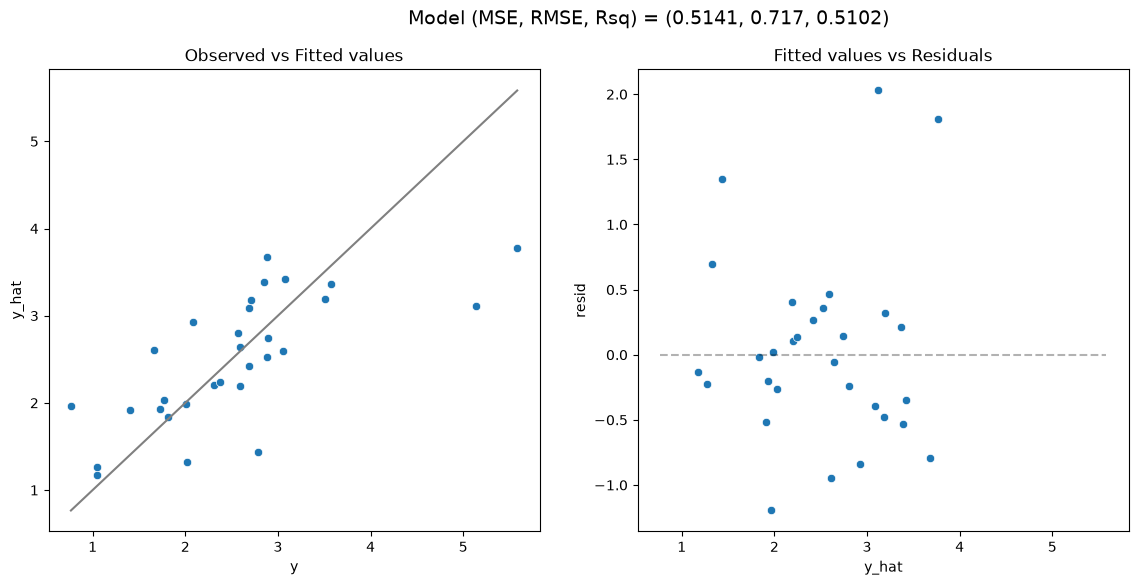

(0.5141325717194642, 0.7170303840978179, 0.510183527152637)

In [24]:
model_fit(gs.best_estimator_, X_test, y_test, plot=True)

### 🚩 Exercise 7 (CORE)

- How does this model compare to the performance of our baseline model? Is it better or worse?

- How do the model coefficients for this model compare to the baseline model? To answer this, create a scatter plot of the coefficients for the baseline model against the coefficients for the ridge model. Are they always higher or lower? Now, use `np.linalg.norm` to compute the $\ell_2$ norm of the coeffcients for both models and comment on the results. 

_Type your answer here_

Our baseline model when predicting based off of test data gave us MSE value of 0.52, and R-squared value of 0.5. Thus compared to this model predicted offf of test data which gave us a MSE of 0.51 and R-squared value of 0.51.

Thus comparing the models, the original model has a marginally higher MSE meaning it has larger residuals, and a lower R-squared value indicating it a worse fit.

In the scatter plot we see that majority of the points are scattered around the grah. This indicates that it depends on feature to feature if the coefficients are higher for the base model, or the cross validation model.

When we apply the l-squared norm, we get single points for all the coefficients. This makese sense, as the norm is a float for each of the coefficiients of the different models. The points norm has higher ``w_df['coef']`` value, meaning the weights are generally higher for the original model.

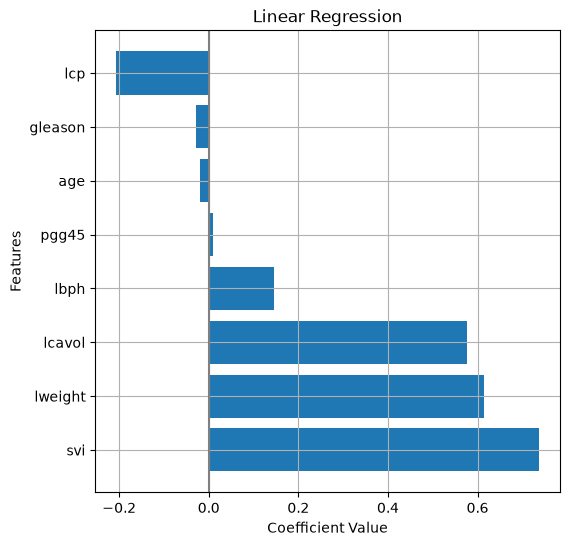

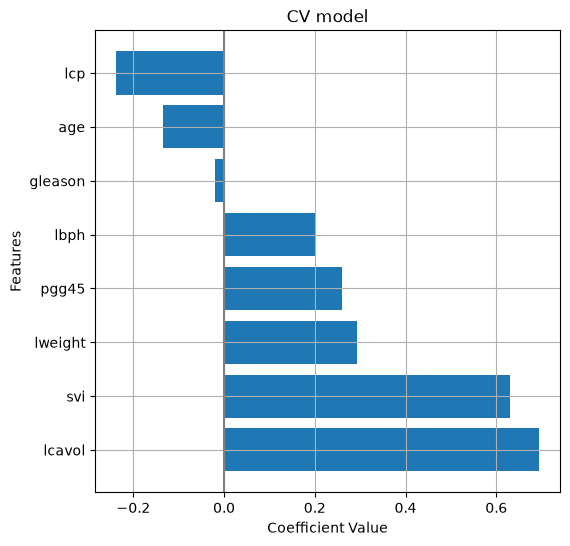

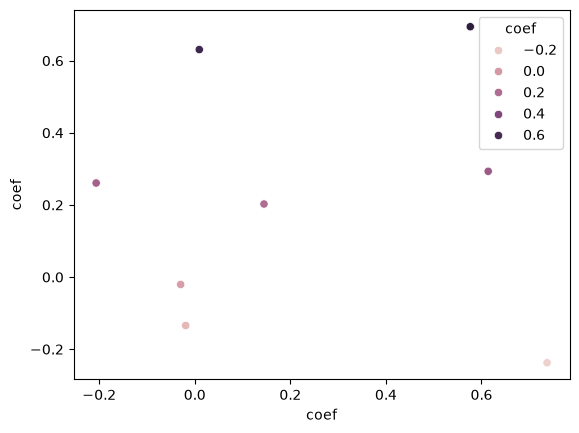

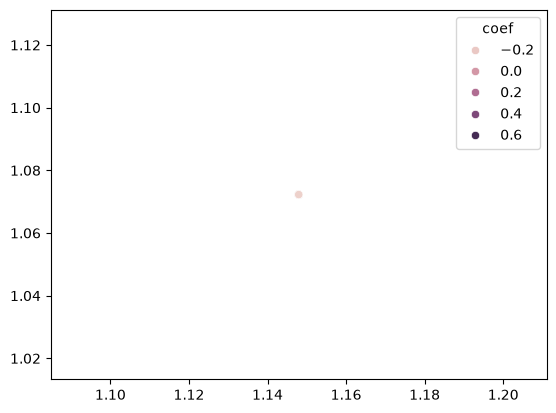

In [25]:
# Code for your answer here!

w_df = get_coefs(lm, plot=True, figsize=(6,6), figtitle="Linear Regression", intercept=False)
#print(w_df['coef'])
w_cv = get_coefs(gs.best_estimator_,  plot=True, figsize=(6,6), figtitle="CV model", intercept=False)

sns.scatterplot(x = w_df['coef'], y = w_cv['coef'], hue = w_cv['coef'])
plt.show()

#x = w_df.__getattribute__('coef')

#print(np.linalg.norm(x))

#now getting the norm
sns.scatterplot(x = np.linalg.norm(w_df['coef']), y = np.linalg.norm(w_cv['coef']), hue = w_cv['coef'])
plt.show()

As we saw last week, it is also recommend to plot the CV scores. Although the grid search may report a best value for the parameter corresponding to the maximum CV score (e.g. min CV MSE), if the curve is relatively flat around the minimum, we prefer the simpler model. 

Recall from last week that we can access the cross-validated scores (along with other results for each split) in the attribute `cv_results_`. 

In [26]:
cv_results = pd.DataFrame(gs.cv_results_)
cv_results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_ridge__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.006214,0.005316,0.004508,0.007069,0.00,{'ridge__alpha': 0.0},-0.933523,-0.684212,-0.732690,-0.424796,-0.789296,-0.712903,0.166571,20
1,0.005732,0.003622,0.002220,0.001184,0.15,{'ridge__alpha': 0.15},-0.936583,-0.689944,-0.730721,-0.419826,-0.785028,-0.712420,0.168506,16
2,0.003040,0.006081,0.006525,0.007995,0.30,{'ridge__alpha': 0.3},-0.939497,-0.695286,-0.729046,-0.415606,-0.780848,-0.712057,0.170243,13
3,0.000776,0.001551,0.006282,0.007697,0.45,{'ridge__alpha': 0.44999999999999996},-0.942272,-0.700271,-0.727639,-0.412013,-0.776750,-0.711789,0.171809,10
4,0.006399,0.006058,0.000000,0.000000,0.60,{'ridge__alpha': 0.6},-0.944917,-0.704931,-0.726475,-0.408949,-0.772727,-0.711600,0.173226,8


In particular, let's examining the `mean_test_score` and the `split#_test_score` keys since these are used to determine the optimal $\alpha$.

In the code below we extract these data into a data frame by selecting our columns of interest along with the $\alpha$ values used (and transform negative MSE values into positive values).

In [ ]:
# Extract only mean and split scores
cv_mse = pd.DataFrame(
    data = gs.cv_results_
).filter(
    # Extract the split#_test_score and mean_test_score columns
    regex = '(split[0-9]+|mean)_test_score'
).assign(
    # Add the alphas as a column
    alpha = alphas
)

cv_mse.update(
    # Convert negative mses to positive
    -1 * cv_mse.filter(regex = '_test_score')
)

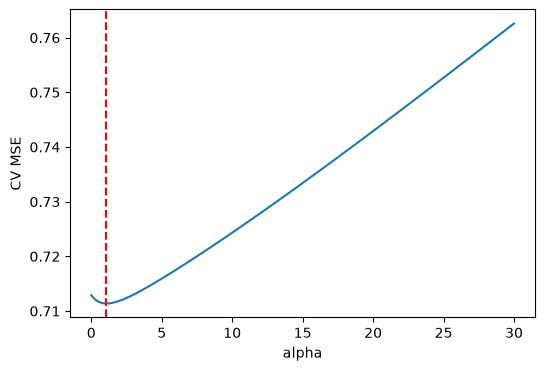

In [28]:
# Plot CV MSE
plt.figure(figsize=(6,4))
ax = sns.lineplot(x='alpha', y='mean_test_score', data=cv_mse)
ax.set_ylabel('CV MSE')
ax.axvline(x=gs.best_params_['ridge__alpha'], color='red', linestyle='dashed', label='Best alpha')
plt.show()

This plot shows that the value of $\alpha=1.05$ corresponds to the minimum of this curve. However, this plot gives us an overly confident view of this particular value of $\alpha$. Specifically, if instead of just plotting the mean MSE across all of the validation sets, we also examine the MSE for each fold individually and the corresponding optimal value of $\alpha$, we see that there is a lot of noise in the MSE and we should take the value $\alpha = 1.05$ with a grain of salt.

### 🚩 Exercise 8 (CORE)

Run the code below to plot the MSE for each validation set in the 5-fold cross validation. Why do you think that our cross validation results are unstable?

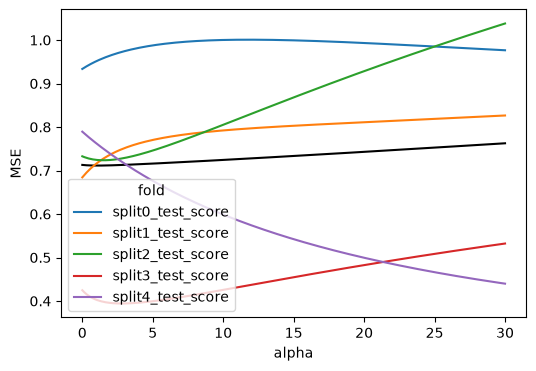

In [29]:
# Reshape the data frame for plotting
d = cv_mse.melt(
    id_vars=('alpha','mean_test_score'),
    var_name='fold',
    value_name='MSE'
)

# Plot the validation scores across folds
plt.figure(figsize=(6,4))
sns.lineplot(x='alpha', y='MSE', color='black', errorbar=None, data = d)  # Plot the mean MSE in black.
sns.lineplot(x='alpha', y='MSE', hue='fold', data = d) # Plot the curves for each fold in different colors
plt.show()

_Type your answer here_

could this be due to multicolinearity? Many different features, cause cross validation results to become unreliable. Another reason they could be unstable is that the no. of data points isn't large enough to effecitvely do K-folding. Here we split into 5 folds, but this could misprepresent the data, as each fold would only contain a smakk no. of datapoints.

### 🚩 Exercise 9 (CORE)

Lastly, try changing the random seed in the cross-validation scheme. Plot the CV MSE with the optimal value of alpha marked with a vertical dashed line. How do the results change? Are different values of `alpha` suggested? Comment on your preffered value of `alpha`.

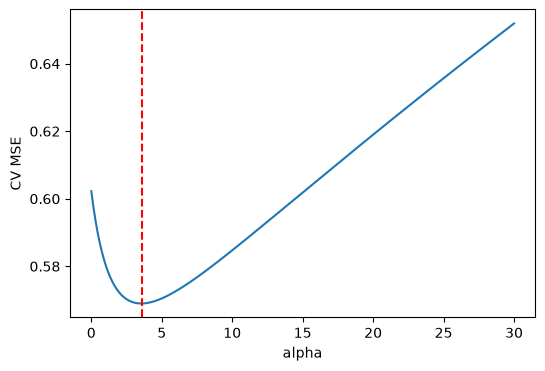

optimal value of alpha is: 3.5999999999999996


In [56]:
# Grid of tuning parameters
alphas = np.linspace(0, 30, num=201)  

#Pipeline
m = make_pipeline(
        preprocessor,
        Ridge())

# CV strategy
cv = KFold(5, shuffle=True, random_state=5)

# Code for your answer here!

# Grid search
gs = GridSearchCV(m,
    param_grid={'ridge__alpha': alphas},
    cv=cv,
    scoring="neg_mean_squared_error")

gs.fit(X_train, y_train)

# Extract only mean and split scores
cv_mse = pd.DataFrame(
    data = gs.cv_results_
).filter(
    # Extract the split#_test_score and mean_test_score columns
    regex = '(split[0-9]+|mean)_test_score'
).assign(
    # Add the alphas as a column
    alpha = alphas
)

cv_mse.update(
    # Convert negative mses to positive
    -1 * cv_mse.filter(regex = '_test_score')
)

# Plot CV MSE
plt.figure(figsize=(6,4))
ax = sns.lineplot(x='alpha', y='mean_test_score', data=cv_mse)
ax.set_ylabel('CV MSE')
ax.axvline(x=gs.best_params_['ridge__alpha'], color='red', linestyle='dashed', label='Best alpha')
plt.show()

print(f'optimal value of alpha is: {gs.best_params_['ridge__alpha']}')


_Type your answer here_

We initially run the cross validation with random state 0, which gives us a optimal alpha of 3.6. We then decide to up the rnadom state to 5, giving us an alpha of 3.6 again. To test whether it will hange we increase the state to 100, which does give us a change, with an alpha of 5.4. Increasing the random state, doesn't make the data more 'random' it just randomises in a different way. Thus we'll choose the alpha of 3.6 as this was obtained for multiple different random states. 

*Note:* Due to the importance of tuning the value of $\alpha$ in ridge regression, sklearn provides a function called [`RidgeCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html) which combines `Ridge` with `GridSearchCV`. However, we will avoid using this function for two reasons:

- it does not allow us to account for additional steps in our pipeline such as standardisation when carrying out cross validation, resulting in _data leakage_.
- it only allows storing all results of the cross-validation in the attribute `.cv_results_` in the case of the default leave-one-out cross validation, with option `store_cv_results=True`. So, if you want to access all results and use a cross-validation strategy other than leave-one-out, you will need to use `GridSearchCV`. 

# Lasso Regression<a id='lasso'></a>

We saw that ridge regression with a wise choice of $\alpha$ can outperform our baseline linear regression. We can now investigate if lasso can yield a more accurate or interpretable solution. Recall that lasso uses an $\ell_1$ penalty on the coefficients, as opposed to the $\ell_2$ penalty of ridge. 

The [`Lasso`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) model is also provided by the `linear_model` submodule and similarly requires the choice of the tuning parameter `alpha` to determine the weight of the $\ell_1$ penalty. 

Try running the code below with different values of $\alpha$ to see how it effects sparsity in the coefficients and model performance.

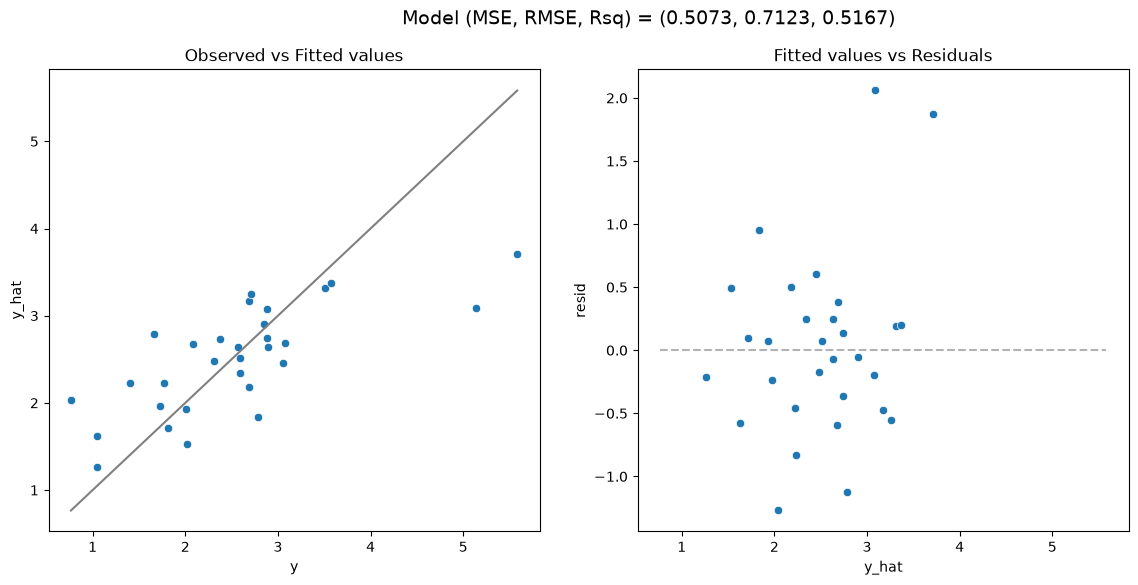

(0.5073090826556591, 0.7122563321274575, 0.5166842966614968)

In [60]:
from sklearn.linear_model import Lasso

# Selected alpha value 
alpha_val = 0.15

# Lasso pipeline
l = make_pipeline(
    preprocessor,
    Lasso(alpha = alpha_val)
).fit(X_train, y_train)

model_fit(l, X_test, y_test, plot = True)

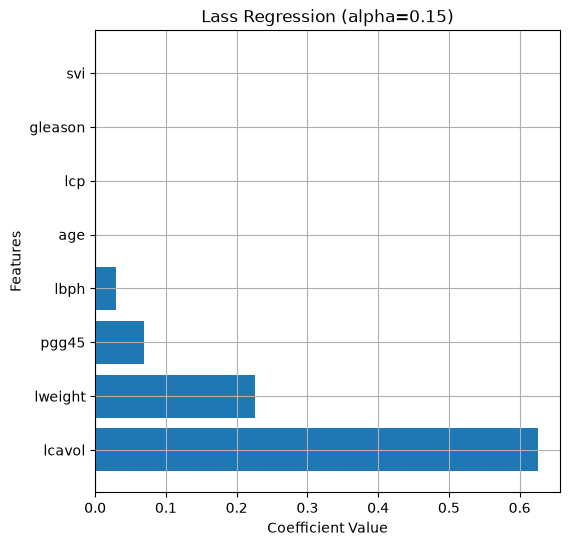

In [61]:
w_dr_r = get_coefs(l, plot=True, figsize=(6,6), figtitle="Lass Regression (alpha="+str(alpha_val)+")", intercept=False)

### 🚩 Exercise 10 (CORE)

a) Plot the solution path of the coefficients as a function of $\alpha$.

b) How does this differ between the solution path for Ridge for large $\alpha$? for small $\alpha$?

c) Which variable seems to be the most important for predicting `lpsa`?

*Note that $\alpha = 0$ causes a warning due to the fitting method (coordinate descent) not converging well without regularisation (the $\ell_1$ penalty here). So, the grid of $\alpha$ values needs to start at some small positive constant.*

C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)


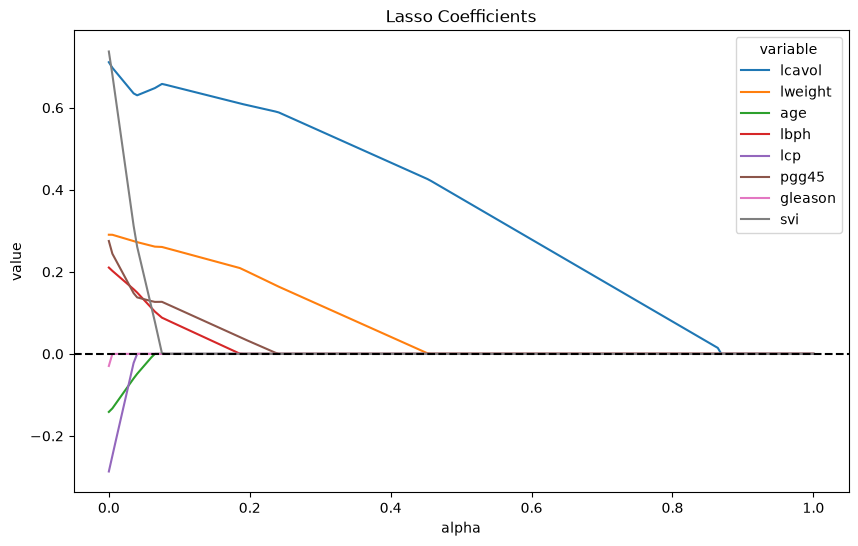

In [63]:
# Code for your answer here!

# Grid of alpha values
alphas = np.linspace(0, 1, num=200) # from 10^-2 to 10^3

ws = [] # Store coefficients
mses_train = [] # Store training mses
mses_test = [] # Store test mses

for a in alphas:
    m = make_pipeline(
        preprocessor,
        Lasso(alpha=a)
    ).fit(X_train, y_train)
    
    ws.append(m[-1].coef_) 
    mses_train.append(mean_squared_error(y_train, m.predict(X_train)))
    mses_test.append(mean_squared_error(y_test, m.predict(X_test)))

# Create a data frame for plotting
sol_path = pd.DataFrame(
    data = ws,
    columns = m[0].get_feature_names_out()
).assign(
    alpha = alphas,
).melt(
    id_vars = ('alpha')
)

# Plot solution path of the weights
plt.figure(figsize=(10,6))
ax = sns.lineplot(x='alpha', y='value', hue='variable', data=sol_path)
ax.axhline(y=0, color = "black", linestyle='dashed')
ax.set_title("Lasso Coefficients")
plt.show()

_Type your answer here_

(b) Looking at solution paths for ridge, we see that all coefficients tend towards zero as alpha approaches infinity. For small alpha the coefficient values act like exp(-x) and -exp(-x), where they curve down towards zero, never reaching. Now looking at the Lasso solutions for the coefficients we see a big difference. As expected all coefficient values eventualy go to zero. They start away from zero, and for small alpha (alpha<1) all coefficients are zeroed by the end. This is expected, as unlike the ridge method lasso allows for the zeroing of coefficients. It subsequentlly follows that for large alpha all coefficients are also zeroed.

(c)
To pick out the variables that seem most important to predicting lpsa, we must look at the varibale coefiicients that take the longest to disapear. Here we notice that the lcavol, and lweight are the two that are non-zero for the longest. Meaning still for these values of alpha, they try to provide information for the fitting model to predict lpsa values. 

## Tuning the Lasso penalty parameter

Again, we can use the `GridSearchCV` function to tune our Lasso model and optimise the $\alpha$ hyperparameter. You could also use [`LassoCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LassoCV.html), which combines `Lasso` and `GridSearchCV` but we will focus on the former to avoid _data leakage_. 

### 🚩 Exercise 11 (CORE)

a) Use `GridSearchCV` to find the optimal value of $\alpha$.  

b) Plot the CV MSE and MSE for each fold. Comment on the stability and uncertainty of $\alpha$ across the different folds. Try changing the value of the `random_state` in the CV strategy - do the results change? are they more or less stable compared with ridge?

c) Which variables are included with this optimal value of $\alpha$?

C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **

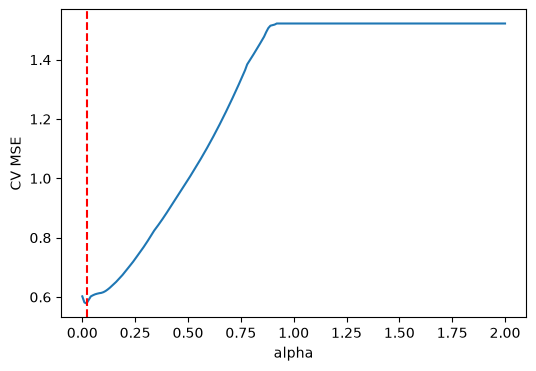

optimal value of alpha is: 0.02


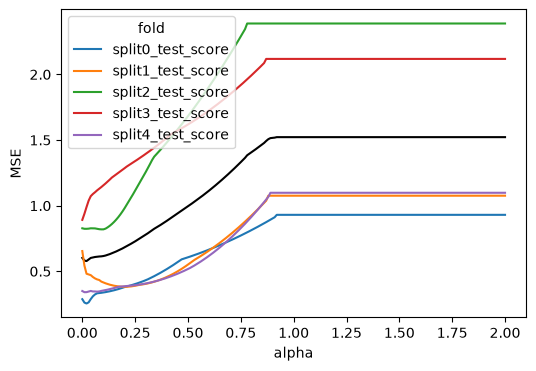

included variables are below:
   Feature  Coefficient
0   lcavol     0.666423
1  lweight     0.282624
2      age    -0.096615
3     lbph     0.180154
4      lcp    -0.135714
5    pgg45     0.196372
7      svi     0.497464


In [78]:
# Code for your answer here!

# Grid of tuning parameters
alphas = np.linspace(0, 2, num=201)  

#Pipeline
m = make_pipeline(
        preprocessor,
        Lasso())

# CV strategy
cv = KFold(5, shuffle=True, random_state=5)

# Code for your answer here!

# Grid search
gs = GridSearchCV(m,
    param_grid={'lasso__alpha': alphas},
    cv=cv,
    scoring="neg_mean_squared_error")

gs.fit(X_train, y_train)

# Extract only mean and split scores
cv_mse = pd.DataFrame(
    data = gs.cv_results_
).filter(
    # Extract the split#_test_score and mean_test_score columns
    regex = '(split[0-9]+|mean)_test_score'
).assign(
    # Add the alphas as a column
    alpha = alphas
)

cv_mse.update(
    # Convert negative mses to positive
    -1 * cv_mse.filter(regex = '_test_score')
)

# Plot CV MSE
plt.figure(figsize=(6,4))
ax = sns.lineplot(x='alpha', y='mean_test_score', data=cv_mse)
ax.set_ylabel('CV MSE')
ax.axvline(x=gs.best_params_['lasso__alpha'], color='red', linestyle='dashed', label='Best alpha')
plt.show()

print(f'optimal value of alpha is: {gs.best_params_['lasso__alpha']}')

# Reshape the data frame for plotting
d = cv_mse.melt(
    id_vars=('alpha','mean_test_score'),
    var_name='fold',
    value_name='MSE'
)

# Plot the validation scores across folds
plt.figure(figsize=(6,4))
sns.lineplot(x='alpha', y='MSE', color='black', errorbar=None, data = d)  # Plot the mean MSE in black.
sns.lineplot(x='alpha', y='MSE', hue='fold', data = d) # Plot the curves for each fold in different colors
plt.show()


best_pipeline = gs.best_estimator_

preprocessor = best_pipeline.named_steps['columntransformer']
lasso_model = best_pipeline.named_steps['lasso']

feature_names = preprocessor.get_feature_names_out()

coefficients = lasso_model.coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

#Filter for included variables (non-zero coefficients)
included_vars = coef_df[coef_df['Coefficient'] != 0]


print('included variables are below:')
print(included_vars)


_Type your answer here_

(a) The optimal value for alpha for the lasso regression is 0.09. 

(b) We plot the 5 different folds as well as the mean MSE which is the black line. We use an ranodom state of 0 here, and see that many of the folds follow the mean MSE very closely, or have a very similar shape. This is true for all bar one which instead of initially going up it loops down and stays much lower than the rest of the folds. We could possibly just discount this one as all the other random folds look similar thus are better represetations of what oculd happen. We see that these folds are substantially more stable than the ridge, as from alpha = 1 onwards all th folds have leveled out and are set at a constant MSE.

Now for changing the random state = 5, we get an optimal alpha value of 0.02. As well as that We see now that alll 5 of our folds are the same shape as the mean MSE as a function of alpha. Further justifying our redundancy of the looping down fold for the previous random state.

### 🚩 Exercise 12 (CORE)

Run the following code to compute the CV MSE for the linear model and compare with the CV MSE of the lasso model to suggest an optimal value of $\alpha$.

In [89]:
# Lasso doesn't allow for alpha=0, so compute CV MSE for linear regression model to compare with Lasso
gs_l = GridSearchCV(
    make_pipeline(
        preprocessor,
        LinearRegression()
    ),
    param_grid = {},
    cv=KFold(5, shuffle=True, random_state=1234),
    scoring="neg_mean_squared_error"
).fit(X_train, y_train)

In [90]:
#Extract the single MSE from Linear Regression (alpha = 0)
lr_mse = -1 * gs_l.best_score_  # Convert neg_mean_squared_error to positive

print(f'MSE for linear regression is {lr_mse}, and lowest MSE for lasso is {-1 * gs.best_score_}')


MSE for linear regression is 0.7129032073597862, and lowest MSE for lasso is 0.578150801401118


_Type your answer here_

SInce we see that the minimum MSE comes from the lasso method, we will chose that, thus choose the optimal value for the lasso parameter alpha which is 0.02 in this case.

# ElasticNet Regression<a id='elasticnet'></a>

Lastly, we can use elastic net regression, which is hybrid between lasso and ridge, including both an $\ell_1$ and $\ell_2$ penalty. The [`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) model is again provided by the `linear_model` submodule and minimises the objective:
$$ \frac{1}{2N} || \mathbf{y} - \mathbf{X}\mathbf{w} ||^2_2 + \alpha \rho ||\mathbf{w}||_1
+ 0.5 \alpha (1 - \rho) ||\mathbf{w}||^2_2.$$

In this parameterisation, $\rho$ determines relative strength of the $\ell_1$ penalty compared to the $\ell_2$ and is referred to as `l1_ratio` in `ElasticNet`. Thus, we can also fit ridge and lasso regression models with `ElasticNet` through appropriate choice of `l1_ratio`:
- ridge corresponds to `l1_ratio=0`
- lasso corresponds to `l1_ratio=1`

The parameter $\alpha$ is referred to as `alpha` in `ElasticNet` and controls the overall penalty relative the residual sum of squares. 

The general `ElasticNet` requires tuning of both `alpha` and `l1_ratio`. 

### 🚩 Exercise 13 (CORE)

The following code plots the solution path for a specific value of `l1_ratio`. Try changing the value of `l1_ratio` (you may also want to change the maximal value of `alpha` for better visualisation). How do the solution paths change?

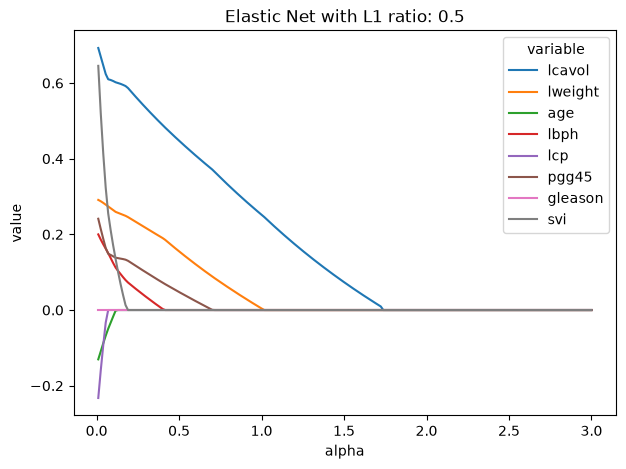

In [94]:
from sklearn.linear_model import ElasticNet

# Grid of alpha values
alphas = np.linspace(0.01, 3, num=200)
# L1 ratio
l = 0.5
ws = [] # Store coefficients
mses_train = [] # Store training mses
mses_test = [] # Store test mses

for a in alphas:
    m = make_pipeline(
        preprocessor,
        ElasticNet(alpha=a, l1_ratio=l)
    ).fit(X_train, y_train)
    
    ws.append(m[-1].coef_) 
    mses_train.append(mean_squared_error(y_train, m.predict(X_train)))
    mses_test.append(mean_squared_error(y_test, m.predict(X_test)))

# Create a data frame with the solution path
sol_path = pd.DataFrame(
    data = ws,
    columns = m[0].get_feature_names_out()
).assign(
    alpha = alphas,
).melt(
    id_vars = ('alpha')
)

# Plot the solution path of the weights
plt.figure(figsize=[7,5])
ax = sns.lineplot(x='alpha', y='value', hue='variable', data=sol_path)
ax.set_title(f'Elastic Net with L1 ratio: {l}')
plt.show()

_Type your answer here_

We see for the original l1_ratio we have it set to one, thus giving us the lasso model. We can also see this as the plots for value with respect to alpha are the exact same. We now change i the l1 ratio to 0 to get the ridge regression, and as expected witht the scaling of the alpha parameter out its the same. Lets now change to 0.5 to actually see the effect of the elasticnet regression. For an l1 ratio of 0.5 we see a somewhat mix of the two methods as expected. Many of the coefficients go to zero quickly which is the same as we saw in the lasso. However the ones that stayed non-zero for larger vlaues of alpha now do the same, but for a greater value of alpha. WIth lcavol goiing to zero at alpha ~~ 1.7.

## Tuning with Grid Search CV

Again, we can use `GridSearchCV` (or [`ElasticNetCV`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNetCV.html)) to tune the parameters. In the following code, we use `GridSearchCV` to tune both `alpha` and `l1_ratio`. 

In [97]:
# Grid of tuning parameters
alphas = np.linspace(0.01, 100, num=50)
l1r = [0.01, .1, .5, .7, .9, .95, 1]

# CV strategy
cv = KFold(5, shuffle=True, random_state=1234)

# Pipeline
m = make_pipeline(
        preprocessor,
        ElasticNet())

# Grid search
gs_enet = GridSearchCV(m,
                        param_grid={'elasticnet__alpha': alphas, 'elasticnet__l1_ratio': l1r},
                        cv = cv,
                        scoring="neg_mean_squared_error",
                        return_train_score=True)
gs_enet.fit(X_train, y_train)

gs_enet.best_params_

{'elasticnet__alpha': np.float64(0.01), 'elasticnet__l1_ratio': 0.01}

Grid search returns the best value, but to better support these choices, let's plot the cv scores as a function of `alpha` for different values of `l1_ratio`.

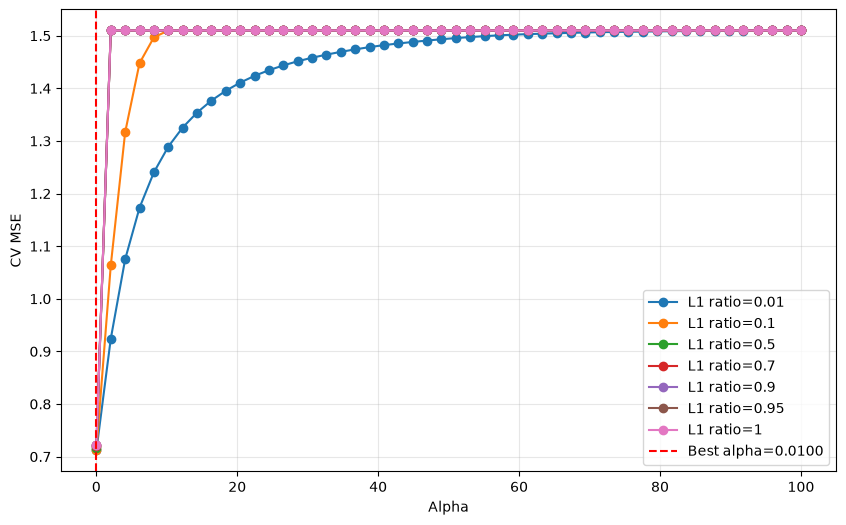

In [98]:
# Extract mean CV scores for each l1_ratio
cv_results_df = pd.DataFrame(gs_enet.cv_results_)
cv_results_df['alpha'] = cv_results_df['param_elasticnet__alpha']
cv_results_df['l1_ratio'] = cv_results_df['param_elasticnet__l1_ratio']

# Convert negative MSE to positive
cv_results_df['mean_cv_mse'] = -cv_results_df['mean_test_score']

# Plot
plt.figure(figsize=(10, 6))
for l1_val in l1r:
    subset = cv_results_df[cv_results_df['l1_ratio'] == l1_val]
    plt.plot(subset['alpha'], subset['mean_cv_mse'], marker='o', label=f'L1 ratio={l1_val}')

plt.axvline(x=gs_enet.best_params_['elasticnet__alpha'], color='red', linestyle='dashed', 
            label=f'Best alpha={gs_enet.best_params_["elasticnet__alpha"]:.4f}')
plt.xlabel('Alpha')
plt.ylabel('CV MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### 🚩 Exercise 14 (CORE)

Comment on the optimal values of `alpha` and `l1_ratio` for ElasticNet based on the plot above. How does the CV MSE of tuned Elastic Net compare to our basineline, ridge, and lasso models? How does the performance of the models compare on the test data?

_Type your answer here_

Looking at the previous blocks of code we see we get a optimal alpha value of 0.01, and optimal l1 ratio of 0.01 aswell.  The reason for the optimal l1 ratio is to do with how it consistently minimises the MSE compared to the other l1 ratio values tested, as alpha changes. However, gfixing alpha to 0.01, we see that all the l1 ratios have very small mse for this optimal alpha value.

Now comparing MSE values we see that ut minimum is jsut above 0.7, where if we expand our plot fo alpha we see that it levels out at an MSE of 1.5 fiited to our trainig data, however fitted to test to levels out at 1.1 For our baseline ridge model predicted on our test data it levels out at mse of around 1.1, and with traiing data around 1.4, which indicates its better than the elsticnet regression. Now looking at the lasso baseline model, we see that it level out around 1.5 MSE, when fitted on training data. When fitted on test data it levels out at around 1.1. Thus all are very similar in their outputs fitted on test and training.

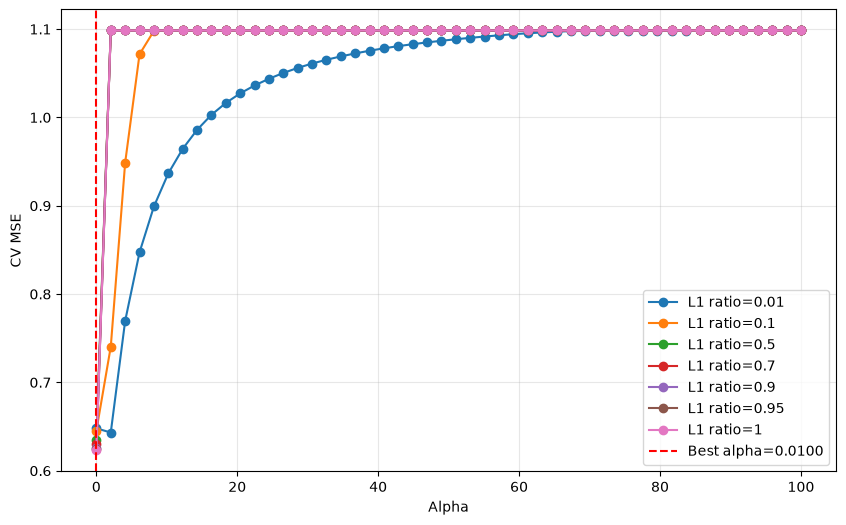

C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
C:\Users\thoma\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **

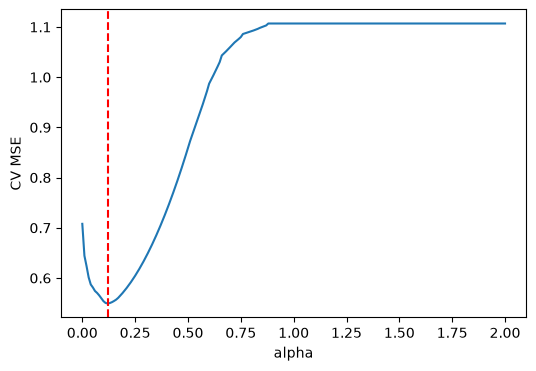

optimal value of alpha is: 0.12


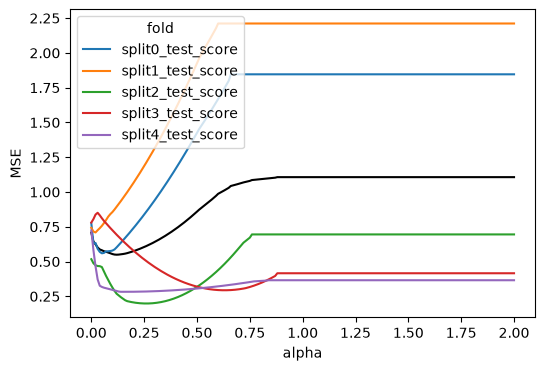

included variables are below:
  Feature  Coefficient
0  lcavol     0.421106
4     lcp     0.336567


In [103]:
# Code for your answer here!

#test data for riddge regression already done in previous cell. 

# Grid of tuning parameters
alphas = np.linspace(0.01, 100, num=50)
l1r = [0.01, .1, .5, .7, .9, .95, 1]

# CV strategy
cv = KFold(5, shuffle=True, random_state=1234)

# Pipeline
m = make_pipeline(
        preprocessor,
        ElasticNet())

# Grid search
gs_enet = GridSearchCV(m,
                        param_grid={'elasticnet__alpha': alphas, 'elasticnet__l1_ratio': l1r},
                        cv = cv,
                        scoring="neg_mean_squared_error",
                        return_train_score=True)
gs_enet.fit(X_test, y_test)

gs_enet.best_params_

# Extract mean CV scores for each l1_ratio
cv_results_df = pd.DataFrame(gs_enet.cv_results_)
cv_results_df['alpha'] = cv_results_df['param_elasticnet__alpha']
cv_results_df['l1_ratio'] = cv_results_df['param_elasticnet__l1_ratio']

# Convert negative MSE to positive
cv_results_df['mean_cv_mse'] = -cv_results_df['mean_test_score']

# Plot
plt.figure(figsize=(10, 6))
for l1_val in l1r:
    subset = cv_results_df[cv_results_df['l1_ratio'] == l1_val]
    plt.plot(subset['alpha'], subset['mean_cv_mse'], marker='o', label=f'L1 ratio={l1_val}')

plt.axvline(x=gs_enet.best_params_['elasticnet__alpha'], color='red', linestyle='dashed', 
            label=f'Best alpha={gs_enet.best_params_["elasticnet__alpha"]:.4f}')
plt.xlabel('Alpha')
plt.ylabel('CV MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Code for your answer here!

# Grid of tuning parameters
alphas = np.linspace(0, 2, num=201)  

#Pipeline
m = make_pipeline(
        preprocessor,
        Lasso())

# CV strategy
cv = KFold(5, shuffle=True, random_state=5)

# Code for your answer here!

# Grid search
gs = GridSearchCV(m,
    param_grid={'lasso__alpha': alphas},
    cv=cv,
    scoring="neg_mean_squared_error")

gs.fit(X_test, y_test)

# Extract only mean and split scores
cv_mse = pd.DataFrame(
    data = gs.cv_results_
).filter(
    # Extract the split#_test_score and mean_test_score columns
    regex = '(split[0-9]+|mean)_test_score'
).assign(
    # Add the alphas as a column
    alpha = alphas
)

cv_mse.update(
    # Convert negative mses to positive
    -1 * cv_mse.filter(regex = '_test_score')
)

# Plot CV MSE
plt.figure(figsize=(6,4))
ax = sns.lineplot(x='alpha', y='mean_test_score', data=cv_mse)
ax.set_ylabel('CV MSE')
ax.axvline(x=gs.best_params_['lasso__alpha'], color='red', linestyle='dashed', label='Best alpha')
plt.show()

print(f'optimal value of alpha is: {gs.best_params_['lasso__alpha']}')

# Reshape the data frame for plotting
d = cv_mse.melt(
    id_vars=('alpha','mean_test_score'),
    var_name='fold',
    value_name='MSE'
)

# Plot the validation scores across folds
plt.figure(figsize=(6,4))
sns.lineplot(x='alpha', y='MSE', color='black', errorbar=None, data = d)  # Plot the mean MSE in black.
sns.lineplot(x='alpha', y='MSE', hue='fold', data = d) # Plot the curves for each fold in different colors
plt.show()


best_pipeline = gs.best_estimator_

preprocessor = best_pipeline.named_steps['columntransformer']
lasso_model = best_pipeline.named_steps['lasso']

feature_names = preprocessor.get_feature_names_out()

coefficients = lasso_model.coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

#Filter for included variables (non-zero coefficients)
included_vars = coef_df[coef_df['Coefficient'] != 0]


print('included variables are below:')
print(included_vars)

### 🚩 Exercise 15 (CORE)

Have you used any form of generative AI when working on this assessment? If so, describe how you used which tool, and what you have learned from it.


_Type your answere here_

Yes generative AI was used to aid plots and to help understand thoertical concepts that needed more explanation than just the notes. 

# Completing the Worksheet

At this point you have hopefully been able to complete all the CORE exercises and attempted the EXTRA ones. Now 
is a good time to check the reproducibility of this document by restarting the notebook's
kernel and rerunning all cells in order.

Before generating the PDF, please **change 'Student 1' and 'Student 2' at the top of the notebook to include your name(s)**.

Once that is done and you are happy with everything, you can then run the following cell 
to generate your PDF.

In [104]:
!jupyter nbconvert --to pdf mlp_week05.ipynb 

[NbConvertApp] Converting notebook mlp_week05.ipynb to pdf
[NbConvertApp] Support files will be in mlp_week05_files\
[NbConvertApp] Making directory .\mlp_week05_files
[NbConvertApp] Writing 133153 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | b had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 1634130 bytes to mlp_week05.pdf
